Stabilization: ID is metadata only. Exact model-predictor groups share one partition, following the lowest-ID member of the original split. All records are retained. See `../outputs/stabilization_report.md`. Run `script_prepare_data.py` first. Hyperparameters, preprocessing and the default 0.5 decision boundary are unchanged.


In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/baseline.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.baseline import DATA_PATH, TABLES, load_split, build_model, save_pipeline, CATEGORICAL, NUMERIC

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

pd.set_option("display.max_columns", None)


df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()

Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


Define target and sensitive attribute

In [2]:
TARGET = "default"

y = df[TARGET]

# Keep sex for fairness auditing, but don't give it to the baseline model
A_sex = df["SEX"]

X = df.drop(columns=["ID", TARGET, "SEX"])

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))

X shape: (30000, 22)
y shape: (30000,)

Target distribution:
default
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [3]:
categorical_features = CATEGORICAL
numeric_features = NUMERIC
print("Predictors:", len(CATEGORICAL) + len(NUMERIC))

Predictors: 22


Train/test split

In [4]:
X_train, X_test, y_train, y_test, metadata_train, metadata_test = load_split(df)
A_train, A_test = metadata_train['SEX'], metadata_test['SEX']
print('Training observations:', len(X_train))
print('Test observations:', len(X_test))
print('Training default rate:', y_train.mean() * 100)
print('Test default rate:', y_test.mean() * 100)


Training observations: 24004
Test observations: 5996
Training default rate: 22.14630894850858
Test default rate: 22.01467645096731


Preprocessing pipeline

continuous financial variables
        ↓
StandardScaler

categorical variables
        ↓
One-Hot Encoding

In [5]:
# Preprocessing and classifier definitions are shared with the standalone scripts.
# StandardScaler for numeric columns; OneHotEncoder(handle_unknown="ignore") for categorical columns.

Logistic Regression

In [6]:
baseline_model = build_model("logistic")
baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

Train

In [7]:
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


Generate predictions

In [8]:
y_pred = baseline_model.predict(X_test)

In [9]:
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print(y_pred[:10])
print(y_prob[:10])

[0 0 0 0 0 0 0 0 0 0]
[0.1452892  0.18092467 0.12963303 0.10235505 0.07077101 0.25477309
 0.10617338 0.06758383 0.09949882 0.10294895]


In [10]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision (AP)": average_precision_score(y_test, y_prob)
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Value"]
)

metrics_df

,Metric,Value
0,Accuracy,0.818045
1,Balanced Accuracy,0.651717
2,Precision,0.661952
3,Recall,0.354545
4,F1,0.461766
5,ROC-AUC,0.756949
6,Average Precision (AP),0.527009


Full classification report

In [11]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Default", "Default"]
    )
)

              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      4676
     Default       0.66      0.35      0.46      1320

    accuracy                           0.82      5996
   macro avg       0.75      0.65      0.68      5996
weighted avg       0.80      0.82      0.80      5996



Confusion matrix

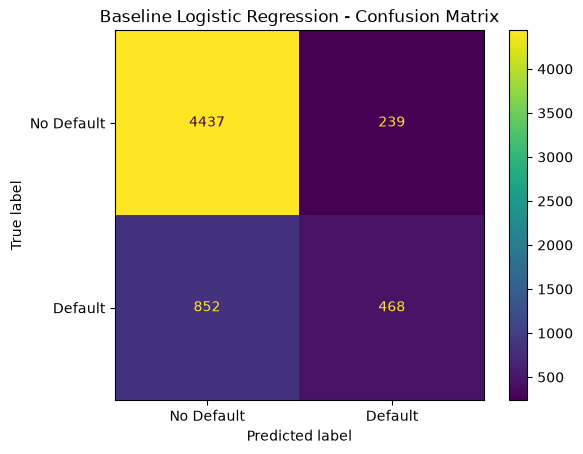

In [12]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot()
plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.show()

ROC curve

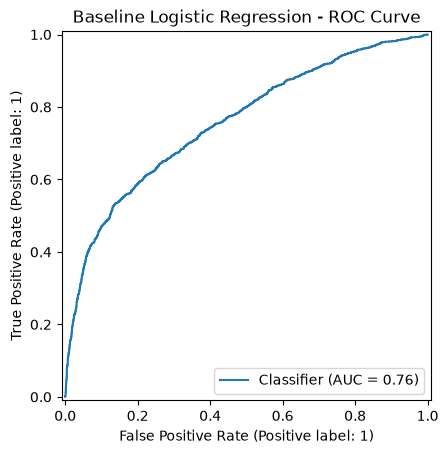

ROC-AUC: 0.7569


In [13]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Baseline Logistic Regression - ROC Curve")
plt.show()

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob), 4)
)

In [14]:
OUTPUT_PATH = ROOT / Path(
    "outputs/tables/baseline_logistic_metrics.csv"
)

metrics_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Saved:", OUTPUT_PATH.resolve())

Saved: C:\Users\Andrei\Desktop\credit-risk-fairness\outputs\tables\baseline_logistic_metrics.csv


In [15]:
predictions = pd.DataFrame({
    "ID": metadata_test["ID"].values,
    "actual": y_test.values,
    "predicted": y_pred,
    "probability_default": y_prob,
    "SEX": A_test.values
})

PRED_PATH = ROOT / Path(
    "outputs/tables/baseline_logistic_predictions.csv"
)

predictions.to_csv(
    PRED_PATH,
    index=False
)

predictions.head()

,ID,actual,predicted,probability_default,SEX
0,6908,0,0,0.145289,1
1,24576,0,0,0.180925,1
2,26767,0,0,0.129633,1
3,2157,1,0,0.102355,2
4,3180,0,0,0.070771,2


In [16]:
save_pipeline(baseline_model, "logistic", X_test, y_pred, y_prob)


Saved and verified fitted pipeline: C:\Users\Andrei\Desktop\credit-risk-fairness\models\baseline_logistic.joblib
